### ASSIGNMENT-2


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from collections import Counter
import itertools

roll = 26017 #M26CSA017
rng = np.random.RandomState(roll)
faces = fetch_olivetti_faces(shuffle=True, random_state=rng)
X = faces.data
y = faces.target
images = faces.images

print(f"features shape: {X.shape}")
print(f"images shape: {images.shape}")
print(f"target shape: {y.shape}")

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
features shape: (400, 4096)
images shape: (400, 64, 64)
target shape: (400,)


In [ ]:
train_idx = []
val_idx = []
test_idx = []

for i in range(40):
    identity_indices = np.where(y == i)[0]
    rng.shuffle(identity_indices)
    train_idx.extend(identity_indices[:6])
    val_idx.extend(identity_indices[6:8])
    test_idx.extend(identity_indices[8:])

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test_clean, y_test = X[test_idx], y[test_idx]

X_test_masked = X_test_clean.copy()
for i in range(len(X_test_masked)):
    img = X_test_masked[i].reshape(64, 64)
    img[24:40, 24:40] = 0.0
    X_test_masked[i] = img.flatten()

print(f"Train size: {X_train.shape}, Val size: {X_val.shape}, Test size: {X_test_clean.shape}")

Train size: (240, 4096), Val size: (80, 4096), Test size: (80, 4096)


In [ ]:
#1.(a)
max_depths = [2, 4, 8, 16, None]
min_samples_leafs = [1, 2, 4]

all_results = []

best_val_acc = -1
best_params = {}
best_tree = None

for md in max_depths:
    for msl in min_samples_leafs:
        dt = DecisionTreeClassifier(max_depth=md, min_samples_leaf=msl, random_state=rng)
        dt.fit(X_train, y_train)

        train_acc = accuracy_score(y_train, dt.predict(X_train))
        val_acc = accuracy_score(y_val, dt.predict(X_val))
        test_acc = accuracy_score(y_test, dt.predict(X_test_clean))

        n_nodes = dt.tree_.node_count
        children_left = dt.tree_.children_left
        children_right = dt.tree_.children_right
        node_samples = dt.tree_.n_node_samples

        leaf_samples = []
        for i in range(n_nodes):
            if children_left[i] == children_right[i]: # Leaf node
                leaf_samples.append(node_samples[i])

        n_leaves = len(leaf_samples)
        mean_samples = np.mean(leaf_samples) if n_leaves > 0 else 0
        fraction_single = (sum(np.array(leaf_samples) == 1) / n_leaves) if n_leaves > 0 else 0

        all_results.append({
            "Max Depth": str(md),
            "Min Samples Leaf": msl,
            "Train Acc": f"{train_acc * 100:.2f}%",
            "Val Acc": f"{val_acc * 100:.2f}%",
            "Test Acc": f"{test_acc * 100:.2f}%",
            "Number of Leaves": n_leaves,
            "Mean Samples/Leaf": f"{mean_samples:.2f}",
            "Fraction Single-Sample Leaves": f"{fraction_single * 100:.2f}%"
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_params = {'max_depth': md, 'min_samples_leaf': msl}
            best_tree = dt

df_grid_results = pd.DataFrame(all_results)
display(df_grid_results)

,Max Depth,Min Samples Leaf,Train Acc,Val Acc,Test Acc,Number of Leaves,Mean Samples/Leaf,Fraction Single-Sample Leaves
0,2,1,7.50%,6.25%,6.25%,3,80.00,0.00%
1,2,2,7.50%,6.25%,5.00%,3,80.00,0.00%
2,2,4,7.50%,6.25%,5.00%,3,80.00,0.00%
3,4,1,12.50%,10.00%,12.50%,5,48.00,0.00%
4,4,2,12.50%,11.25%,11.25%,5,48.00,0.00%
5,4,4,12.50%,8.75%,10.00%,5,48.00,0.00%
6,8,1,22.50%,18.75%,17.50%,9,26.67,0.00%
7,8,2,22.50%,17.50%,16.25%,9,26.67,0.00%
8,8,4,22.50%,21.25%,16.25%,9,26.67,0.00%
9,16,1,42.50%,32.50%,21.25%,17,14.12,0.00%


In [ ]:
print(f"\nChosen Best Hyperparameters Based on Val Acc:")
print(f"Best settings: {best_params}")

train_acc = accuracy_score(y_train, best_tree.predict(X_train))
val_acc = accuracy_score(y_val, best_tree.predict(X_val))
test_acc = accuracy_score(y_test, best_tree.predict(X_test_clean))

print(f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, Test Acc: {test_acc:.4f}")

n_nodes = best_tree.tree_.node_count
children_left = best_tree.tree_.children_left
children_right = best_tree.tree_.children_right
node_samples = best_tree.tree_.n_node_samples

is_leaves = np.zeros(shape=n_nodes, dtype=bool)
leaf_samples = []
for i in range(n_nodes):
    if children_left[i] == children_right[i]:
        is_leaves[i] = True
        leaf_samples.append(node_samples[i])

n_leaves = sum(is_leaves)
mean_samples_per_leaf = np.mean(leaf_samples)
fraction_single_sample_leaves = sum(np.array(leaf_samples) == 1) / n_leaves

print(f"Number of leaves: {n_leaves}")
print(f"Mean samples per leaf: {mean_samples_per_leaf:.2f}")
print(f"Fraction of leaves with 1 example: {fraction_single_sample_leaves:.4f}")


Chosen Best Hyperparameters Based on Val Acc:
Best settings: {'max_depth': None, 'min_samples_leaf': 2}
Train Acc: 0.9917, Val Acc: 0.6750, Test Acc: 0.6250
Number of leaves: 43
Mean samples per leaf: 5.58
Fraction of leaves with 1 example: 0.0000


# What happens with increased Depth?

As depths increases, the decision tree becomes more complex and fits the training data more accurately. Training accuracy will rapidly approach 1. However, validation and test accuracy will initially increase and then plateau or decrease due to overfitting.

The number of leaves will increase significantly. Consequently, the mean number of samples per leaf will decrease, and the fraction of leaves containing exactly one training example will approach 1.0 , indicating that the tree is memorizing individual training points as well as noise rather than learning patterns.

In [ ]:
#1.(b)
B_values = [1, 5, 10, 25, 50, 100, 200]
N = len(X_train)

ensemble = []
bootstrap_indices_list = []
distinct_samples_counts = []

for _ in range(max(B_values)):

    boot_idx = rng.choice(N, size=N, replace=True)
    bootstrap_indices_list.append(boot_idx)
    distinct_samples_counts.append(len(np.unique(boot_idx)))

    dt = DecisionTreeClassifier(**best_params, random_state=roll)
    dt.fit(X_train[boot_idx], y_train[boot_idx])
    ensemble.append(dt)

def predict_ensemble(models, X_data):
    predictions = np.array([model.predict(X_data) for model in models])
    maj_vote = [Counter(predictions[:, i]).most_common(1)[0][0] for i in range(X_data.shape[0])]
    return np.array(maj_vote)

for B in B_values:
    current_ensemble = ensemble[:B]

    train_pred = predict_ensemble(current_ensemble, X_train)
    val_pred = predict_ensemble(current_ensemble, X_val)
    test_pred = predict_ensemble(current_ensemble, X_test_clean)

    avg_distinct = np.mean(distinct_samples_counts[:B])

    print(f"B={B:3d} | Train: {accuracy_score(y_train, train_pred):.4f} | "
          f"Val: {accuracy_score(y_val, val_pred):.4f} | Test: {accuracy_score(y_test, test_pred):.4f} | "
          f"Avg Distinct Samples: {avg_distinct:.2f}")


B=  1 | Train: 0.7250 | Val: 0.3250 | Test: 0.4500 | Avg Distinct Samples: 152.00
B=  5 | Train: 0.9542 | Val: 0.5375 | Test: 0.5875 | Avg Distinct Samples: 152.00
B= 10 | Train: 1.0000 | Val: 0.6750 | Test: 0.7000 | Avg Distinct Samples: 153.10
B= 25 | Train: 1.0000 | Val: 0.8125 | Test: 0.8000 | Avg Distinct Samples: 153.28
B= 50 | Train: 1.0000 | Val: 0.8250 | Test: 0.8500 | Avg Distinct Samples: 152.84
B=100 | Train: 1.0000 | Val: 0.8500 | Test: 0.8750 | Avg Distinct Samples: 152.44
B=200 | Train: 1.0000 | Val: 0.8625 | Test: 0.8875 | Avg Distinct Samples: 152.39



OOB, Disagreement, and Vote Margin:


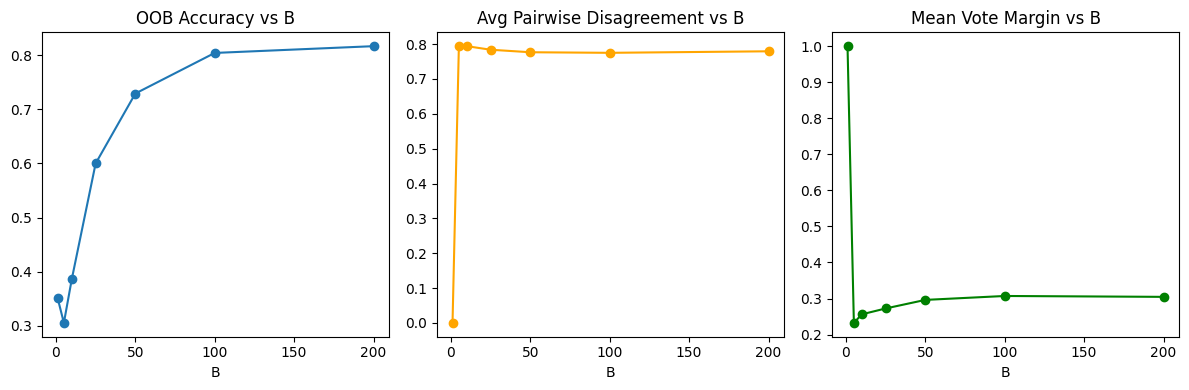

Selected Final Ensemble Size: B=100


In [ ]:
#1.(c)
print(f"\nOOB, Disagreement, and Vote Margin:")

oob_accuracies = []
avg_disagreements = []
mean_margins = []

N = len(X_train)

for B in B_values:
    current_ensemble = ensemble[:B]
    current_boot_indices = bootstrap_indices_list[:B]
    oob_preds = np.zeros((N, 40))
    oob_counts = np.zeros(N)

    for b_idx in range(B):

        in_bag = set(current_boot_indices[b_idx])
        oob_idx = [i for i in range(N) if i not in in_bag]

        preds = current_ensemble[b_idx].predict(X_train[oob_idx])
        for idx, p in zip(oob_idx, preds):
            oob_preds[idx, p] += 1
            oob_counts[idx] += 1

    valid_oob_mask = oob_counts > 0
    final_oob_preds = np.argmax(oob_preds[valid_oob_mask], axis=1)
    oob_acc = accuracy_score(y_train[valid_oob_mask], final_oob_preds)
    oob_accuracies.append(oob_acc)


    if B == 1:
        avg_disagreements.append(0)
    else:
        val_preds = np.array([model.predict(X_val) for model in current_ensemble])
        disagreements = 0
        pairs = 0
        for i, j in itertools.combinations(range(B), 2):
            disagreements += np.mean(val_preds[i] != val_preds[j])
            pairs += 1
        avg_disagreements.append(disagreements / pairs)

    val_preds = np.array([model.predict(X_val) for model in current_ensemble])
    margins = []
    for i in range(X_val.shape[0]):
        counts = Counter(val_preds[:, i])
        if len(counts) == 1:
            margins.append(1.0)
        else:
            top2 = counts.most_common(2)
            margin = (top2[0][1] / B) - (top2[1][1] / B)
            margins.append(margin)
    mean_margins.append(np.mean(margins))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(B_values, oob_accuracies, marker='o')
plt.title("OOB Accuracy vs B")
plt.xlabel("B")

plt.subplot(1, 3, 2)
plt.plot(B_values, avg_disagreements, marker='o', color='orange')
plt.title("Avg Pairwise Disagreement vs B")
plt.xlabel("B")

plt.subplot(1, 3, 3)
plt.plot(B_values, mean_margins, marker='o', color='green')
plt.title("Mean Vote Margin vs B")
plt.xlabel("B")
plt.tight_layout()
plt.show()

final_B = 100
print(f"Selected Final Ensemble Size: B={final_B}")

In [ ]:
#1.(d)
print(f"\n Robustness on Clean vs Masked Data:")

if 'final_B' not in globals():
    final_B = 100

final_ensemble = ensemble[:final_B]

def get_predictions_and_confidence(models, X_data):
    predictions = np.array([model.predict(X_data) for model in models])
    final_preds = []
    confidences = []
    vote_counts_list = []

    for i in range(X_data.shape[0]):
        counts = Counter(predictions[:, i])
        top_class, top_count = counts.most_common(1)[0]
        final_preds.append(top_class)
        confidences.append(top_count / final_B)
        vote_counts_list.append(counts)

    return np.array(final_preds), np.array(confidences), vote_counts_list

tree_clean_pred = best_tree.predict(X_test_clean)
tree_mask_pred = best_tree.predict(X_test_masked)

print(f"Single Tree - Clean Acc: {accuracy_score(y_test, tree_clean_pred):.4f}")
print(f"Single Tree - Masked Acc: {accuracy_score(y_test, tree_mask_pred):.4f}")

bag_clean_pred, bag_clean_conf, bag_clean_votes = get_predictions_and_confidence(final_ensemble, X_test_clean)
bag_mask_pred, bag_mask_conf, bag_mask_votes = get_predictions_and_confidence(final_ensemble, X_test_masked)

print(f"Bagged Model - Clean Acc: {accuracy_score(y_test, bag_clean_pred):.4f}, Mean Conf: {np.mean(bag_clean_conf):.4f}")
print(f"Bagged Model - Masked Acc: {accuracy_score(y_test, bag_mask_pred):.4f}, Mean Conf: {np.mean(bag_mask_conf):.4f}")

tree_wrong_bag_right = np.where((tree_clean_pred != y_test) & (bag_clean_pred == y_test))[0]
tree_wrong_bag_wrong = np.where((tree_clean_pred != y_test) & (bag_clean_pred != y_test))[0]

print("\n Case Analysis:")
print("2 Faces where Bagging CORRECTS the tree:")
for idx in tree_wrong_bag_right[:2]:
    print(f"Index: {idx}, True: {y_test[idx]}, Tree Pred: {tree_clean_pred[idx]}, Bag Pred: {bag_clean_pred[idx]}")
    print(f"Bagging Votes: {bag_clean_votes[idx]}")

print("\n2 Faces where BOTH are WRONG:")
for idx in tree_wrong_bag_wrong[:2]:
    print(f"Index: {idx}, True: {y_test[idx]}, Tree Pred: {tree_clean_pred[idx]}, Bag Pred: {bag_clean_pred[idx]}")
    print(f"Bagging Votes: {bag_clean_votes[idx]}")


 Robustness on Clean vs Masked Data:
Single Tree - Clean Acc: 0.6250
Single Tree - Masked Acc: 0.6000
Bagged Model - Clean Acc: 0.8750, Mean Conf: 0.3801
Bagged Model - Masked Acc: 0.8875, Mean Conf: 0.2807

 Case Analysis:
2 Faces where Bagging CORRECTS the tree:
Index: 0, True: 0, Tree Pred: 12, Bag Pred: 0
Bagging Votes: Counter({np.int64(0): 35, np.int64(17): 12, np.int64(1): 7, np.int64(3): 7, np.int64(37): 6, np.int64(5): 5, np.int64(16): 4, np.int64(11): 4, np.int64(15): 4, np.int64(8): 3, np.int64(4): 3, np.int64(19): 2, np.int64(39): 2, np.int64(22): 2, np.int64(20): 1, np.int64(7): 1, np.int64(36): 1, np.int64(32): 1})
Index: 3, True: 1, Tree Pred: 23, Bag Pred: 1
Bagging Votes: Counter({np.int64(1): 42, np.int64(23): 18, np.int64(14): 10, np.int64(15): 6, np.int64(31): 4, np.int64(0): 3, np.int64(17): 2, np.int64(12): 2, np.int64(26): 2, np.int64(20): 2, np.int64(28): 1, np.int64(13): 1, np.int64(35): 1, np.int64(37): 1, np.int64(8): 1, np.int64(33): 1, np.int64(10): 1, np.

In [ ]:
import numpy as np

# Prepare the dictionary containing outputs structured by question sections
q1_results = {
    # 1.(a) Grid search results, best params, and metrics
    '1.(a)_grid_results_df': df_grid_results.to_json(),
    '1.(a)_best_params': str(best_params),
    '1.(a)_tree_train_acc': train_acc,
    '1.(a)_tree_val_acc': val_acc,
    '1.(a)_tree_test_acc': test_acc,

    # 1.(b) Ensemble performance across B values
    '1.(b)_B_values': np.array(B_values),
    '1.(b)_avg_distinct_samples': np.array(distinct_samples_counts),

    # 1.(c) OOB metrics, disagreements, and margins
    '1.(c)_oob_accuracies': np.array(oob_accuracies),
    '1.(c)_avg_disagreements': np.array(avg_disagreements),
    '1.(c)_mean_margins': np.array(mean_margins),
    '1.(c)_selected_final_B': final_B,

    # 1.(d) Robustness comparison & case analysis predictions
    '1.(d)_y_test': y_test,
    '1.(d)_tree_clean_pred': tree_clean_pred,
    '1.(d)_tree_mask_pred': tree_mask_pred,
    '1.(d)_bag_clean_pred': bag_clean_pred,
    '1.(d)_bag_mask_pred': bag_mask_pred,
    '1.(d)_bag_clean_conf': bag_clean_conf,
    '1.(d)_bag_mask_conf': bag_mask_conf,
    '1.(d)_tree_wrong_bag_right': tree_wrong_bag_right,
    '1.(d)_tree_wrong_bag_wrong': tree_wrong_bag_wrong
}

# Save to npz file with explicit section-based keys
np.savez('resultsQ1.npz', **q1_results)
print("Successfully saved structured results grouped by sections to resultsQ1.npz!")

Successfully saved structured results grouped by sections to resultsQ1.npz!
